# 02 · Tensile-test analysis, node by node

**Goal.** Make the method behind each computed property inspectable: what each analysis node does, on which part of the curve it works, and where it fails. The nodes run one at a time on three specimens, and each step is plotted.

**Audience.** Materials scientists and engineers (MSE experts) who want to judge the numbers that the overview notebook reports.

**Prerequisites.** The terms of the tensile test (ISO 6892-1: ReH, ReL, Rp0.2, Rm, Ag, Agt). No RDF or workflow knowledge is needed. The `pmd-demonstrator` environment, and the Ontodocker access variables `ONTODOCKER_ADDRESS` and `ONTODOCKER_TOKEN` set before Jupyter starts.

**Reading paths.** MSE experts: [05](05-tensile-analysis-overview.ipynb) → **02** → [01](01-tensile-data-from-graphs.ipynb). Workflow developers: [03](03-tensile-workflow-building.ipynb) → [04](04-tensile-workflow-knowledge-graph.ipynb) → **02** → [05](05-tensile-analysis-overview.ipynb).

| Specimen | Orientation | Why it is here |
| --- | --- | --- |
| Zx3 | in rolling direction | the reference case (clear discontinuous yielding, straight elastic part) |
| Zy3 | perpendicular to rolling direction | the method misses its yield peak |
| Zd3 | diagonal to rolling direction | its elastic part is not straight |

| Section | Nodes | Part of the curve |
| --- | --- | --- |
| 1. Data | `get_specimen_record`, `get_reported_properties`, `fetch_curve` | – |
| 2. Units | the signature of `final_elastic_fit` | – |
| 3. Extensometer validity and yield | `count_dropped_samples`, `extensometer_validity`, `bootstrap_fit`, `yield_analysis` | strain record, low-stress loading, yield region |
| 4. E (elastic slope) and Rp0.2 | `final_elastic_fit`, `proof_strength`, `window_sensitivity` | elastic part, first 0.2 % of plastic strain |
| 5. Maximum force | `maximum_force`, `elongation_at_maximum_force` | force maximum |
| 6. Cross-section and lab comparison | `s0_scatter`, `compare_with_reported` | specimen metadata, lab values |
| 7. The same numbers in the workflow | `specimen_workflow` | – |

All properties are **method-defined, ISO 6892-1-inspired** (method specification v2.6). Nothing here claims conformity with ISO 6892-1 or its Annex G.

*Execution class: network-read.* SPARQL queries to Ontodocker and curve downloads from the public data host (sections 1 and 7); all other sections compute locally. Nothing is written to remote services or to disk.

## Setup

Select the `pmd-demonstrator` kernel. The environment installs `pmd_tensile` (`environment.yml`), so it is imported like any other package. The nodes come from its public modules `acquisition`, `analysis` and `workflows`; `demo` holds the table and plotting helpers.

The second code cell is tagged `parameters` for papermill. The source is the three Ontodocker datasets of the PMDco 2 description of the tests. The package reads the Ontodocker address and token from the environment; this notebook prints neither.

*Execution class: read-only (local).*

In [1]:
import dataclasses
import inspect
import os

import pandas as pd
from IPython.display import display
from semantikon.converter import parse_input_args, parse_output_args

from pmd_tensile import acquisition, analysis, demo, workflows

pd.set_option("display.max_colwidth", None)  # flags and lab notes are long
pd.set_option("display.precision", 4)

In [2]:
profile_id = "pmdco2-tto"
source = {
    "kind": "ontodocker",
    "datasets": [
        "pmdco2_tto_example_parallel",
        "pmdco2_tto_example_perpendicular",
        "pmdco2_tto_example_diagonal",
    ],
}

## 1. Data for three specimens

The acquisition nodes turn the graph content of one specimen into neutral records in fixed units (N, mm, mm², strain as a ratio, MPa, GPa, %):

- `get_specimen_record`: S0, the cross-section measurements s1–s3, L0, Lu, Su, orientation, lab notes and the curve location;
- `get_reported_properties`: the lab-reported values, used only for the comparison in section 6;
- `fetch_curve`: the raw curve, downloaded into memory, with the SHA-256 of its bytes.

A node is a plain Python function: called directly, it runs without a workflow. The same records can be built from the PMDco 3 description of these tests; notebook 01 shows how. The specimen table of all ten tests is read only to give every specimen the same colour as in notebook 05.

*Execution class: network-read (SPARQL queries to Ontodocker; three curve downloads from the data host).*

In [3]:
if source["kind"] == "ontodocker" and not os.getenv(demo.ONTODOCKER_ADDRESS_ENV, "").strip():
    raise RuntimeError("Set ONTODOCKER_ADDRESS (and ONTODOCKER_TOKEN if required) before starting Jupyter.")

tour_ids = ["Zx3", "Zy3", "Zd3"]

specimens = demo.specimen_table(profile_id, source)
colors = demo.specimen_colors(dict(zip(specimens["specimen_id"], specimens["orientation"])))

records, reported, curves = {}, {}, {}
for sid in tour_ids:
    records[sid] = acquisition.get_specimen_record(profile_id, source, sid)
    reported[sid] = acquisition.get_reported_properties(profile_id, source, sid)
    curves[sid] = acquisition.fetch_curve(records[sid])
retrieved = pd.Timestamp.now(tz="Europe/Berlin").floor("s")

display(pd.DataFrame({
    sid: {
        "orientation": record.orientation,
        "S0 / mm²": record.s0_mm2,
        "s1..s3 / mm²": record.cross_section_measurements_mm2,
        "L0 / mm": record.l0_mm,
        "lab notes": "; ".join(record.notes),
        "samples": len(curves[sid].force_n),
        "curve": curves[sid].source_url,
        "SHA-256 (start)": curves[sid].sha256[:16],
    }
    for sid, record in records.items()
}))
print("data retrieved:", retrieved)

,Zx3,Zy3,Zd3
orientation,in rolling direction,perpendicular to rolling direction,diagonal to rolling direction
S0 / mm²,120.396,120.663,120.707
s1..s3 / mm²,"(120.323, 120.431, 120.433)","(120.581, 120.581, 120.826)","(120.867, 120.544, 120.71)"
L0 / mm,60.0,60.0,60.0
lab notes,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.","Proben aus Stahlblech entnommen, entgegen der Walzrichtung","Proben aus Stahlblech entnommen, diagonal der Walzrichtung"
samples,13134,12110,12257
curve,https://data.pmds-mpcdf-2.pyiron.com/Zx3.csv,https://data.pmds-mpcdf-2.pyiron.com/Zy3.csv,https://data.pmds-mpcdf-2.pyiron.com/Zd3.csv
SHA-256 (start),d0b3aaa7d4e871ec,ad617593ecc08a2e,d4c6535319663a08


data retrieved: 2026-11-10 00:29:07+01:00


## 2. The analysis nodes declare units on their numeric ports

The analysis nodes are typed Python functions. Their arrays and scalars are annotated with semantikon's `u(type, units=..., uri=...)`: a unit and a QUDT quantity kind. The table below is read from the annotations of `final_elastic_fit` itself: force in N, strain as a ratio (`Unitless`), S0 in mm², E in GPa. The quantity kind of E, `ModulusOfElasticity`, classifies the dimension; it does not make the regression slope a material modulus. Its other inputs are result types of earlier nodes (`Bootstrap`, `Yielding`) and the method parameters. Notebook 04 shows what becomes of these annotations in the workflow's knowledge graph.

*Execution class: read-only (local).*

In [4]:
node = analysis.final_elastic_fit
print(f"{node.__module__}.{node.__name__}{inspect.signature(node)}")

inputs = parse_input_args(node)
ports = [("input", name, annotation) for name, annotation in inputs.items()]
ports += [("output", name, annotation) for name, annotation in zip(node.flowrep_recipe.outputs, parse_output_args(node))]
display(pd.DataFrame([
    {
        "direction": direction,
        "port": name,
        "type": getattr(annotation["dtype"], "__name__", str(annotation["dtype"])).replace("pmd_tensile.analysis.", ""),
        "unit": annotation.get("units", "–"),
        "quantity kind (QUDT)": str(annotation.get("uri", "–")).rsplit("/", 1)[-1],
    }
    for direction, name, annotation in ports
]))

pmd_tensile.analysis.final_elastic_fit(force_n: 'ForceArray', strain: 'StrainArray', s0_mm2: 'AreaMM2', k_ext: 'int', bootstrap: 'Bootstrap', yielding: 'Yielding', params: 'AnalysisParameters | None' = None) -> 'tuple[ElasticResult, ModulusGPa, StrainRatio]'


,direction,port,type,unit,quantity kind (QUDT)
0,input,force_n,ndarray,N,Force
1,input,strain,ndarray,Unitless,Strain
2,input,s0_mm2,float,mm**2,Area
3,input,k_ext,int,–,–
4,input,bootstrap,Bootstrap,–,–
5,input,yielding,Yielding,–,–
6,input,params,AnalysisParameters | None,–,–
7,output,elastic,ElasticResult,–,–
8,output,e_gpa,float,GPa,ModulusOfElasticity
9,output,strain_origin,float,Unitless,Strain


## 3. Extensometer validity and yield

- **`count_dropped_samples`** (M1) counts the non-finite samples per channel. No smoothing is applied anywhere.
- **`extensometer_validity`** (M2, M3) splits the record into windows of 0.1 mm crosshead travel. The extensometer counts as removed from the first window from which on, until the end of the record, the strain no longer follows the crosshead (ratio below 0.05) or is missing, zero or drops by more than 0.001 in one step. That sample is `k_ext`; every property that needs strain uses only the samples before it. A strain channel that vendor software continues from the crosshead cannot be detected.
- **`bootstrap_fit`** (M5, steps 1–2) takes Fm from the force alone and fits a provisional line E₀, b₀ in the window 10–40 % of 0.5·Rm on the first loading branch. The robust scatter of its residuals, s_n = 1.4826·MAD, is the noise level, fixed here for the yield search. The noise level is the residual scatter of the provisional fit, so it also picks up anything else that bends the curve in that window.
- **`yield_analysis`** (M7–M9) calls yielding discontinuous if, above 0.5·Rm, the stress falls below its running maximum M by more than d = max(0.005·M, 5·s_n), with the peak at a plastic strain of at most 0.5 %, followed by at least 0.05 % of plastic flow. ReH is the maximum stress before that first decrease; ReL is the lowest stress during yielding, ignoring the initial transient. Otherwise yielding is continuous, and ReH and ReL are NaN with a flag.

`params` holds the method parameters. It comes from the node `analysis_parameters`, which converts the workflow's JSON-able `parameters` input; `None` gives the method defaults.

*Execution class: read-only (local).*

,Zx3,Zy3,Zd3
non-finite strain samples,11228,10124,10226
k_ext (first sample without valid strain),1869,1966,2024
largest valid strain / %,3.8429,3.8708,4.1968
last recorded strain / %,3.9052,3.906,4.2056
noise level s_n / MPa,0.4802,4.875,1.1025
yield type,discontinuous,continuous,discontinuous
ReH / MPa,379.4088,NaN,396.21
ReL / MPa,370.7641,NaN,389.7225
flags,extensometer:extensometer_ended_early; extensometer:near_rate_switch,extensometer:extensometer_ended_early; extensometer:near_rate_switch; reh:extensometer_invalid; reh:no_upper_yield; rel:no_upper_yield,extensometer:extensometer_ended_early; extensometer:near_rate_switch


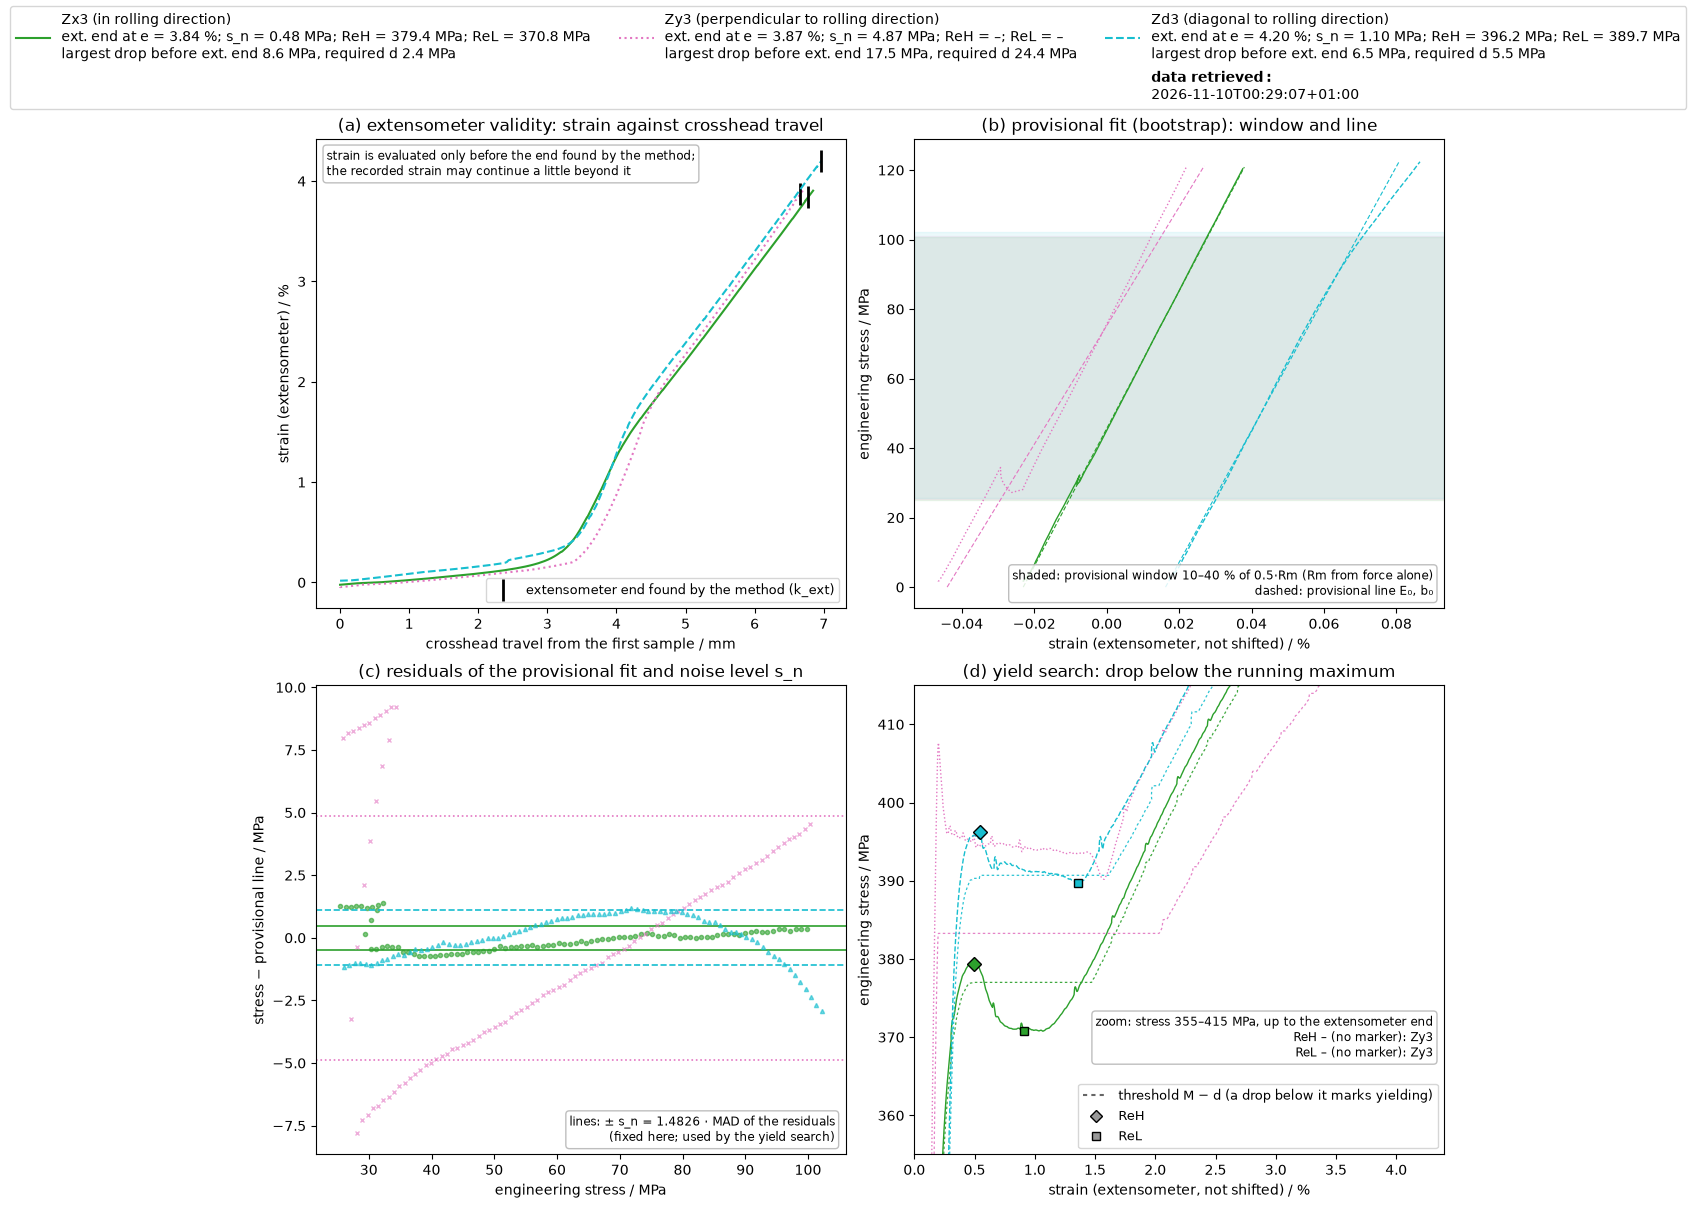

In [5]:
params = workflows.analysis_parameters(None)  # the method defaults, as in the workflow

a_percent, dropped, extensometer, bootstrap, yielding = {}, {}, {}, {}, {}
for sid in tour_ids:
    record, curve = records[sid], curves[sid]
    a_percent[sid] = workflows.percent_value(analysis.elongation_after_fracture(record.l0_mm, record.lu_mm))
    dropped[sid] = analysis.count_dropped_samples(curve.force_n, curve.strain, curve.crosshead_mm)
    extensometer[sid], k_ext, _ = analysis.extensometer_validity(
        curve.strain, curve.crosshead_mm, record.l0_mm, a_percent[sid], record.rate_switch_strain, params
    )
    bootstrap[sid], _ = analysis.bootstrap_fit(curve.force_n, curve.strain, record.s0_mm2, k_ext, params)
    yielding[sid], _, _, _ = analysis.yield_analysis(
        curve.force_n, curve.strain, record.s0_mm2, k_ext, bootstrap[sid], record.rate_switch_strain, params
    )

display(pd.DataFrame({
    sid: {
        "non-finite strain samples": dropped[sid]["strain"],
        "k_ext (first sample without valid strain)": extensometer[sid].k_ext,
        "largest valid strain / %": 100 * extensometer[sid].max_valid_strain,
        "last recorded strain / %": 100 * pd.Series(curves[sid].strain).dropna().iloc[-1],
        "noise level s_n / MPa": bootstrap[sid].noise_mpa,
        "yield type": yielding[sid].yield_type,
        "ReH / MPa": yielding[sid].reh_mpa,
        "ReL / MPa": yielding[sid].rel_mpa,
        "flags": "; ".join(extensometer[sid].flags + yielding[sid].flags),
    }
    for sid in tour_ids
}))
fig = demo.yield_step_figure(
    records, curves, extensometer, bootstrap, yielding, params=params, colors=colors, retrieved=retrieved
)

How to read the figure: (a) the method's extensometer end k_ext (|) lies at 3.84–4.20 % strain, up to one 0.1 mm crosshead window before the last recorded strain (table); after the last recorded strain the record has no strain values (section 5 shows the consequence). (b, c) The provisional fit and its residuals; the lines in (c) are ± s_n. (d) The stress up to the extensometer end and, dashed, the threshold M − d; a fall below it marks yielding. The legend gives, per specimen, the largest drop below M before the extensometer end and the required d there.

- **Zx3** falls well below its threshold just after the peak: discontinuous yielding, with ReH and ReL marked.
- **Zy3: a real yield peak is missed.** The curve has a clear stress maximum of 407.6 MPa at 0.20 % strain (extensometer strain, not shifted), followed by a drop and a plateau, and the lab reports ReH 408 MPa, yet the method reports continuous yielding. At about 34 MPa the force falls by about 21 % within 0.07 s while the crosshead keeps moving (from the raw curve, not shown): the step in (b) and the large residuals in (c). This lies inside the provisional fit window, so the noise level becomes 4.9 MPa, against 0.48 MPa on Zx3 and 1.1 MPa on Zd3. The required drop becomes 24.4 MPa, more than the 17.5 MPa that occurs before the extensometer end, so the search runs on to the force maximum. That is why the flag `reh:extensometer_invalid` appears; the extensometer was working at the peak. ReH and ReL are NaN.
- **Zd3:** its curved elastic part (section 4) raises the noise level to 1.1 MPa, so it passes the yield test only narrowly (drop 6.5 MPa, required 5.5 MPa). The weakness is therefore not specific to Zy3.

The result is reported as the approved method gives it, because changing the method after seeing this comparison would make a new agreement with the lab uninformative.

## 4. E (elastic slope) and Rp0.2

- **`final_elastic_fit`** (M4–M6) fits σ = E·e + b by least squares on the first loading branch, in the stress window 10–40 % of a reference stress: ReH for discontinuous yielding, Rp0.2 for continuous yielding (found by fixed-point iteration). The strain origin is e₀ = −b/E. E is reported as *the regression slope of the elastic part (mE-type), not Annex-G-conformant*, not as a material modulus.
- **`proof_strength`** (M10) finds the first crossing of 0.2 % plastic strain, e − e₀ − σ/E = 0.002, interpolated linearly, and flags `in_yield_plateau` when a discontinuous curve crosses during its yield range.
- **`window_sensitivity`** (M15) repeats the fit on a grid of windows (lower bound 5, 10 or 15 %, upper bound 30, 40 or 50 % of the same reference stress). It reports the ranges of E and Rp0.2, and `e_linearity_rel_diff`, the relative difference of E between the windows 5–25 % and 25–50 %. It describes sensitivity only and never selects a window. Because it also reports the induced ranges of Ag and Agt, it takes the outputs of the two maximum-force nodes, which run here and are discussed in section 5.

The method parameters are a node input. The loop at the end of the next cell calls `window_sensitivity` once per window with a one-window grid, without changing any code, to show E in each window (panel c).

*Execution class: read-only (local).*

,Zx3,Zy3,Zd3
E / GPa,200.0756,205.0917,158.6705
lab E / GPa,199.0,206.0,195.0
R²,1.0,1.0,0.9954
points in the window,132,136,138
window / MPa,"(37.9, 151.8)","(39.6, 158.3)","(39.6, 158.5)"
strain origin e₀ / %,-0.0226,-0.037,0.009
E range over the grid / GPa,"(197.6, 201.0)","(175.2, 206.5)","(152.0, 180.1)"
e_linearity_rel_diff,0.0018,0.2636,-0.1411
Rp0.2 / MPa,375.8609,395.7685,395.447
Rp0.2 range over the grid / MPa,"(375.8, 376.0)","(395.4, 395.8)","(394.4, 395.6)"


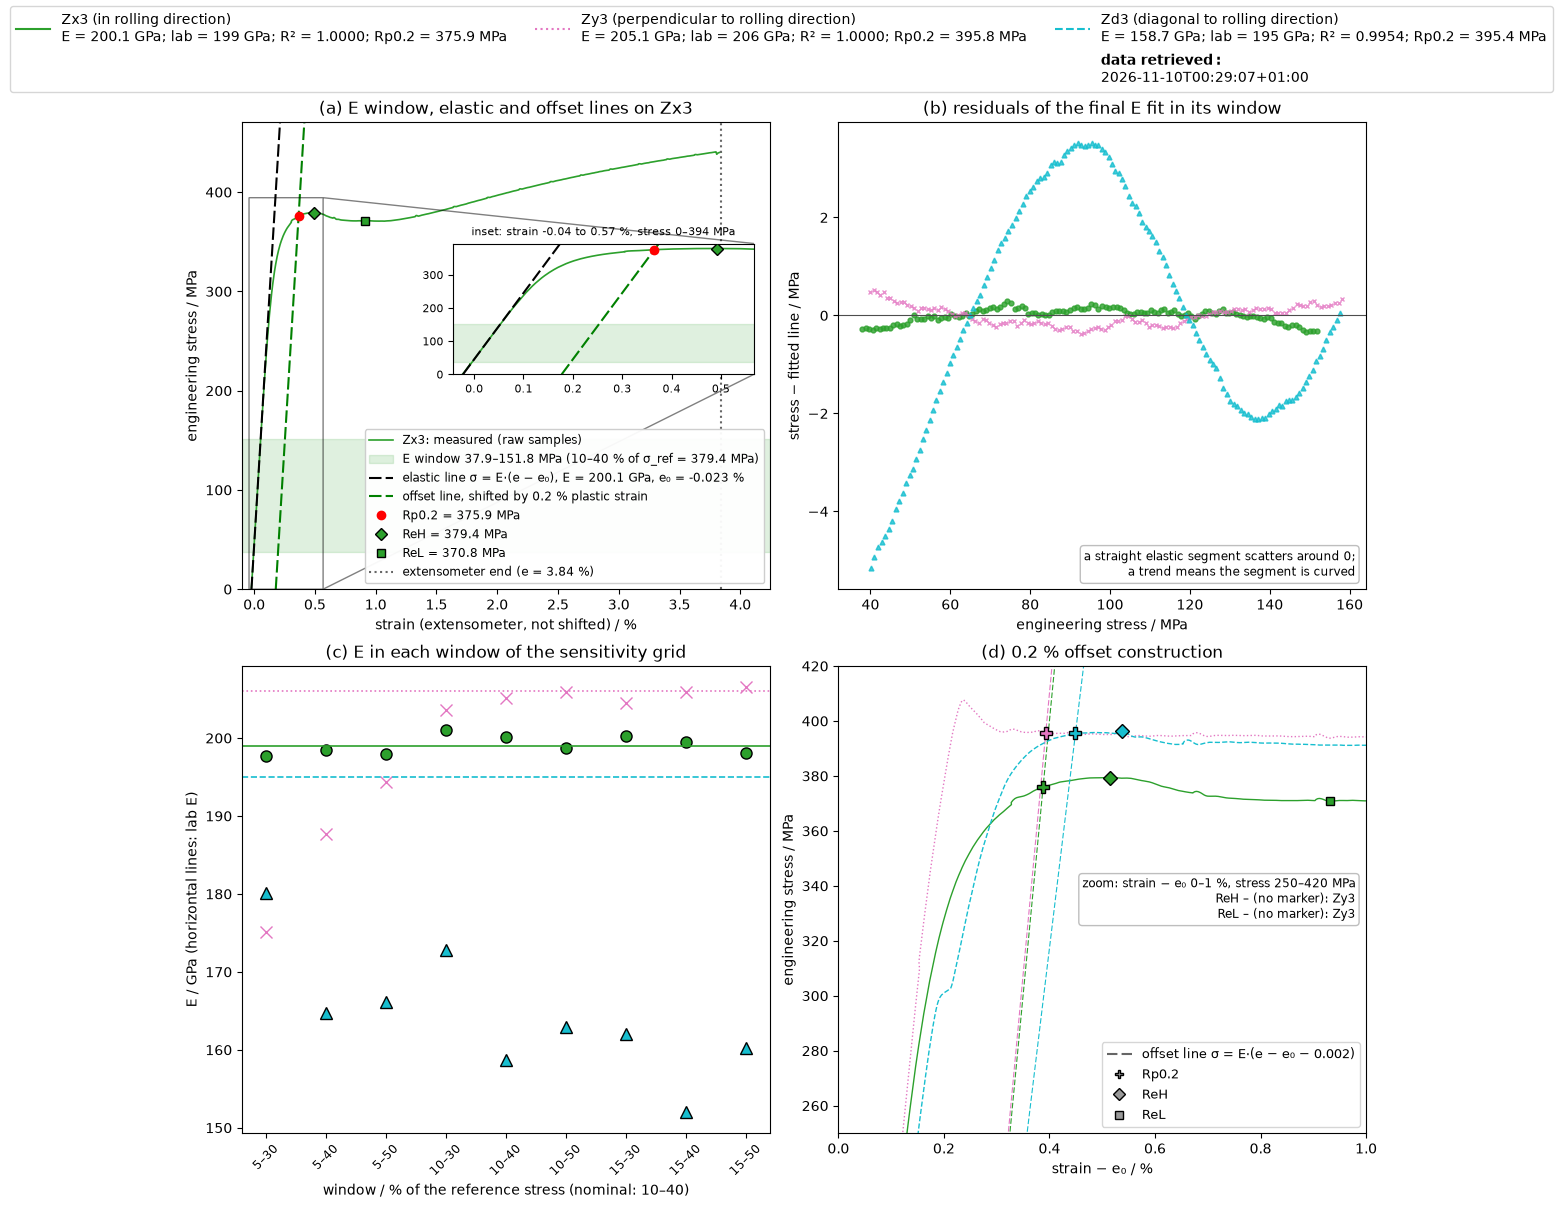

In [6]:
elastic, proof, maximum, elongation, sensitivity = {}, {}, {}, {}, {}
for sid in tour_ids:
    record, curve, k_ext = records[sid], curves[sid], extensometer[sid].k_ext
    force_n, strain, s0_mm2 = curve.force_n, curve.strain, record.s0_mm2
    elastic[sid], _, _ = analysis.final_elastic_fit(force_n, strain, s0_mm2, k_ext, bootstrap[sid], yielding[sid], params)
    proof[sid], _ = analysis.proof_strength(
        force_n, strain, s0_mm2, k_ext, elastic[sid], yielding[sid], record.rate_switch_strain, params
    )
    maximum[sid], _, _ = analysis.maximum_force(force_n, s0_mm2, yielding[sid])
    elongation[sid], _, _ = analysis.elongation_at_maximum_force(
        force_n, strain, k_ext, bootstrap[sid], elastic[sid], maximum[sid], params
    )
    sensitivity[sid] = analysis.window_sensitivity(
        force_n, strain, s0_mm2, k_ext, elastic[sid], maximum[sid], elongation[sid], params
    )

display(pd.DataFrame({
    sid: {
        "E / GPa": elastic[sid].fit.e_gpa,
        "lab E / GPa": reported[sid].e_gpa,
        "R²": elastic[sid].fit.r2,
        "points in the window": elastic[sid].fit.n,
        "window / MPa": (round(elastic[sid].fit.lo_mpa, 1), round(elastic[sid].fit.hi_mpa, 1)),
        "strain origin e₀ / %": 100 * elastic[sid].strain_origin,
        "E range over the grid / GPa": tuple(round(e, 1) for e in sensitivity[sid].e_range_gpa),
        "e_linearity_rel_diff": sensitivity[sid].linearity_rel_diff,
        "Rp0.2 / MPa": proof[sid].rp02_mpa,
        "Rp0.2 range over the grid / MPa": tuple(round(r, 1) for r in sensitivity[sid].rp02_range_mpa),
        "flags": "; ".join(elastic[sid].flags + proof[sid].flags + sensitivity[sid].flags),
    }
    for sid in tour_ids
}))

window_moduli = []
for sid in tour_ids:
    record, curve, k_ext = records[sid], curves[sid], extensometer[sid].k_ext
    for f_lo in params.window_grid_lo:
        for f_hi in params.window_grid_hi:
            one_window = dataclasses.replace(params, window_grid_lo=(f_lo,), window_grid_hi=(f_hi,))
            result = analysis.window_sensitivity(
                curve.force_n, curve.strain, record.s0_mm2, k_ext, elastic[sid], maximum[sid], elongation[sid], one_window
            )
            window_moduli.append({"specimen_id": sid, "f_lo": f_lo, "f_hi": f_hi, "e_gpa": result.e_range_gpa[0]})
window_moduli = pd.DataFrame(window_moduli)

fig = demo.elastic_step_figure(
    records, curves, extensometer, yielding, elastic, proof, window_moduli, reported,
    method_specimen="Zx3", params=params, colors=colors, retrieved=retrieved,
)

- **Zx3** (panel a and its inset): the fit window is shaded; the elastic line follows the elastic part, and the offset line, shifted by 0.2 % plastic strain, crosses the curve at Rp0.2. Its residuals in (b) stay within a few tenths of an MPa, and its E changes little between windows (c).
- **Zd3: E is `outside` (section 6); its elastic part is not straight.** The computed 158.7 GPa (lab 195 GPa, −18.6 %) is reported as the method gives it, but it should not be read as a modulus. The curvature shows in the trend of the residuals (b), in R² = 0.9954, in `e_linearity_rel_diff` = −0.14, and in a window range of 152–180 GPa that does not contain the lab value (c). No flag marks this, because the method has no rule for it. The cause of the curvature is unknown: settling or slip of the extensometer or grips, bending and local deformation all remain possible. How the lab obtained 195 GPa is also unknown.
- **Zy3:** the nominal E window starts above the low-load event of section 3. The low end of its E range (175 GPa) and `e_linearity_rel_diff` = +0.26 come from windows that include the event (c). Its Rp0.2 of 395.8 MPa lies on the plateau after the peak (d), so it is a plateau stress, although the flag `in_yield_plateau` is missing: for the method, Zy3 yields continuously.

## 5. Maximum force, and why Ag and Agt are empty

- **`maximum_force`** (M11) takes Fm from the force channel alone: the largest force after work hardening begins (with continuous yielding, over all samples), and Rm = Fm/S0. It reads no strain itself; only the start of work hardening comes from `yield_analysis`, whose classification uses strain. So Fm is defined although the strain record ends long before the force maximum.
- **`elongation_at_maximum_force`** (M12) reads Agt and Ag at the strain mid-point of the band of samples near the force maximum. It needs valid strain over the whole band.

On all three specimens the strain record ends at about 3.9–4.2 % (section 3), long before the force maximum (panel b). So **Ag and Agt are NaN**, with the flags `ag:extensometer_invalid` and `agt:extensometer_invalid`; they are not estimated from the crosshead. For Zx3 the lab note records the removal of the extensometer after 3.9 % strain; for Zy3 and Zd3, removal is our inference, not a statement of the graphs.

*Execution class: read-only (local).*

,Zx3,Zy3,Zd3
Fm / N,60627.81,60930.2,61734.63
Rm / MPa,503.57,504.9618,511.442
Ag / %,NaN,NaN,NaN
Agt / %,NaN,NaN,NaN
flags,ag:extensometer_invalid; agt:extensometer_invalid,ag:extensometer_invalid; agt:extensometer_invalid,ag:extensometer_invalid; agt:extensometer_invalid


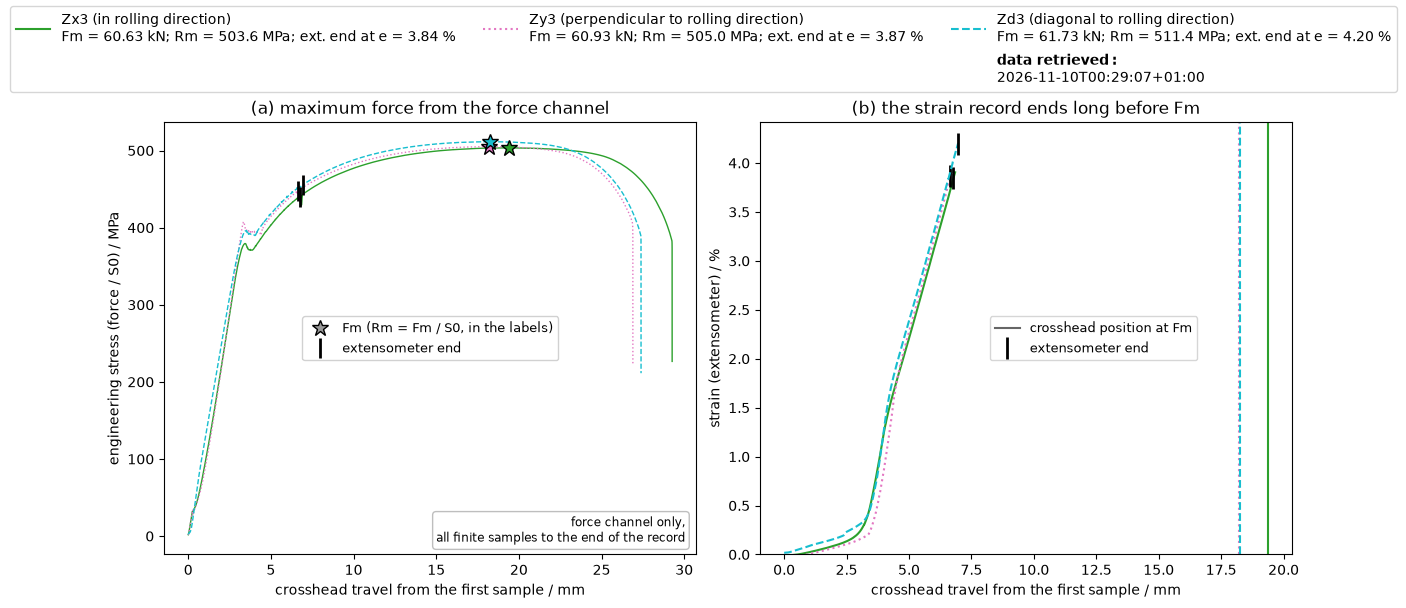

In [7]:
display(pd.DataFrame({
    sid: {
        "Fm / N": maximum[sid].fm_n,
        "Rm / MPa": maximum[sid].rm_mpa,
        "Ag / %": elongation[sid].ag_percent,
        "Agt / %": elongation[sid].agt_percent,
        "flags": "; ".join(maximum[sid].flags + elongation[sid].flags),
    }
    for sid in tour_ids
}))
fig = demo.maximum_force_step_figure(records, curves, extensometer, maximum, colors=colors, retrieved=retrieved)

## 6. Cross-section and comparison with the lab

- **`s0_scatter`** (M14) gives u(S0) = sd(s1..s3)/√3, the within-specimen dimensional scatter of the mean (ν = 2); it excludes instrument bias. As a relative uncertainty it applies equally to every stress-based value, including E; strains are unaffected. It is one to two orders of magnitude smaller than plausible force-class and E effects, and the lab value uses the same S0, so this component cannot explain a difference from it.
- **`compare_with_reported`** (§13) compares each computed value with the lab's value, against tolerances fixed before any real data were analysed: Fm ±0.1 %, Rm ±(0.1 % + 0.5 MPa), ReH and Rp0.2 ±2 %, E ±10 % (barely discriminating: Zd3's 5–30 % window gives 180.1 GPa, which would be `within`; section 4, panel c), A and Z rounding-aware. ReL is not compared, because no lab values exist. This is a **consistency check with the lab's software, not a validation**: the lab values are not ground truth.

`assemble_curve_analysis` collects the step results into one record, from which the workflow's adapter node `computed_properties` takes the compared values. A and Z come from the metadata (L0, Lu, S0, Su).

*Execution class: read-only (local).*

,Zx3,Zy3,Zd3
S0 / mm²,120.396,120.663,120.707
s1..s3 / mm²,"(120.323, 120.431, 120.433)","(120.581, 120.581, 120.826)","(120.867, 120.544, 120.71)"
u(S0)/S0 / 10⁻⁴,3.0182,6.7682,7.7257
u(S0) / mm²,0.0363,0.0817,0.0933
resulting u of Rm / MPa,0.152,0.3418,0.3951


S0 scatter: within-specimen dimensional scatter of the mean (nu = 2); excludes instrument bias


computed                     reported                    \
specimen_id       Zx3       Zy3       Zd3      Zx3      Zy3      Zd3   
quantity                                                               
fm_n         60627.81   60930.2  61734.63  60680.0  60935.0  61681.0   
rm_mpa         503.57  504.9618   511.442    504.0    505.0    511.0   
reh_mpa      379.4088       NaN    396.21    379.0    408.0    396.0   
rp02_mpa     375.8609  395.7685   395.447    376.0      NaN      NaN   
e_gpa        200.0756  205.0917  158.6705    199.0    206.0    195.0   
a_percent     35.1667   33.5667   33.2833     35.0     33.5     33.0   
z_percent     58.0534   58.2598   63.6111     58.0     58.0     64.0   

            deviation / %                outcome                  \
specimen_id           Zx3    Zy3     Zd3     Zx3             Zy3   
quantity                                                           
fm_n               -0.086 -0.008   0.087  within          within   
rm_mpa             -0.085 -0.008   0.086  within          within   
reh_mpa             0.108    NaN   0.053  within  not_comparable   
rp02_mpa           -0.037    NaN     NaN  within  not_comparable   
e_gpa               0.541 -0.441 -18.631  within          within   
a_percent           0.476  0.199   0.859  within          within   
z_percent           0.092  0.448  -0.608  within          within   

                             
specimen_id             Zd3  
quantity                     
fm_n                 within  
rm_mpa               within  
reh_mpa              within  
rp02_mpa     not_comparable  
e_gpa               outside  
a_percent            within  
z_percent            within

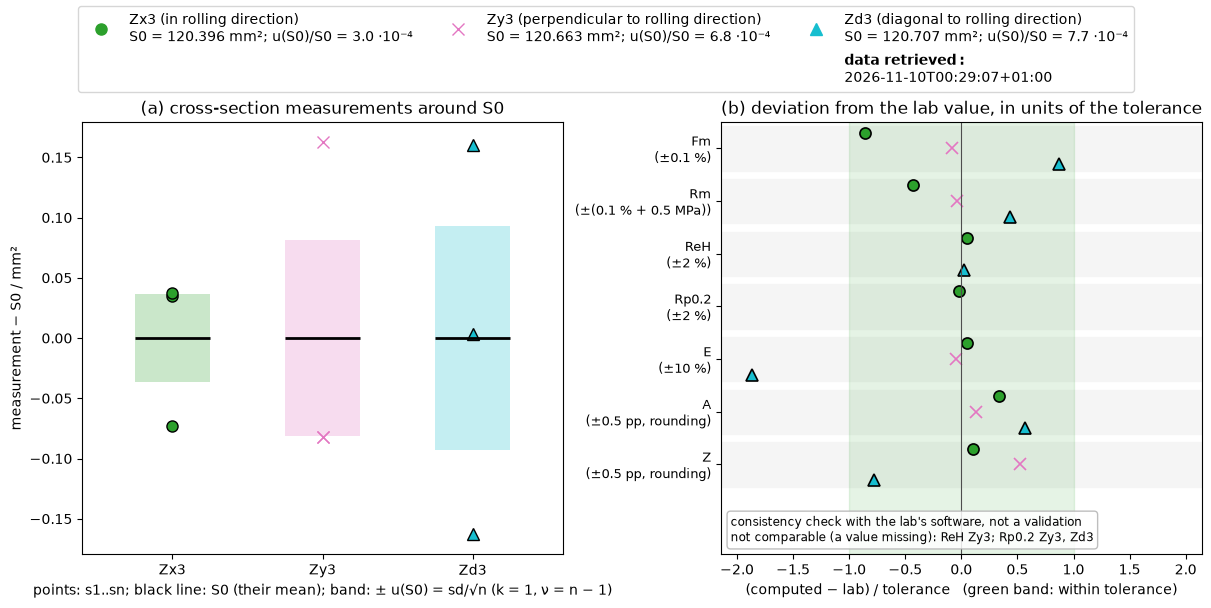

In [8]:
scatter, curve_analysis, comparisons = {}, {}, []
for sid in tour_ids:
    record = records[sid]
    scatter[sid] = analysis.s0_scatter(record.s0_mm2, record.cross_section_measurements_mm2)
    curve_analysis[sid] = analysis.assemble_curve_analysis(
        dropped[sid], extensometer[sid], bootstrap[sid], yielding[sid], elastic[sid], proof[sid],
        maximum[sid], elongation[sid], sensitivity[sid],
    )
    a = analysis.elongation_after_fracture(record.l0_mm, record.lu_mm)
    z = analysis.reduction_of_area(record.s0_mm2, record.su_mm2)
    computed = workflows.computed_properties(curve_analysis[sid], a, z)
    comparisons.append(analysis.compare_with_reported(computed, reported[sid]).assign(specimen_id=sid))
comparison = pd.concat(comparisons, ignore_index=True)

display(pd.DataFrame({
    sid: {
        "S0 / mm²": records[sid].s0_mm2,
        "s1..s3 / mm²": records[sid].cross_section_measurements_mm2,
        "u(S0)/S0 / 10⁻⁴": 1e4 * scatter[sid].u_rel,
        "u(S0) / mm²": scatter[sid].u_rel * records[sid].s0_mm2,
        "resulting u of Rm / MPa": scatter[sid].u_rel * maximum[sid].rm_mpa,
    }
    for sid in tour_ids
}))
print("S0 scatter:", analysis.S0_SCATTER_LABEL)

deviation_percent = (100 * comparison["rel_deviation"]).round(3) + 0.0  # + 0.0 removes -0.0
display(
    comparison.assign(**{"deviation / %": deviation_percent})
    .pivot(index="quantity", columns="specimen_id", values=["computed", "reported", "deviation / %", "outcome"])
    .reindex(index=comparison["quantity"].unique())
    .reindex(columns=tour_ids, level="specimen_id")
)
fig = demo.lab_comparison_step_figure(records, scatter, comparison, colors=colors, retrieved=retrieved)

Panel (b) shows each deviation in units of its tolerance, so the green band is `within`. Zd3's E lies outside it (section 4). Zy3's ReH is `not_comparable`, which is neither agreement nor disagreement; for the Rp0.2 of Zy3 and Zd3 the lab gives no value. `within` only says that two evaluations of the same raw curve with the same S0 agree inside the tolerance; errors they share cannot show up. Nor need the two start from identical data: the computed Fm is the maximum of the published force channel (notebook 05 checks this on all ten specimens), and the lab's Fm differs from it in both directions (the Fm deviations above). So the lab's Fm is not the maximum of the published file; the lab may have evaluated differently processed data.

## 7. The same numbers in the workflow

The nodes above are the steps of the per-specimen workflow `specimen_workflow` (notebook 03 builds it). Run once per specimen, it queries and downloads the data again and must give exactly the result assembled here by hand. The comparison uses the full text representation of the result, which contains every value, flag and diagnostic.

*Execution class: network-read (SPARQL queries and one curve download per specimen).*

In [9]:
for sid in tour_ids:
    run = demo.build_specimen_node(f"specimen_{sid}").run(profile_id=profile_id, source=source, specimen_id=sid)
    same_curve = run.outputs.curve_sha256 == curves[sid].sha256
    same_result = repr(run.outputs.analysis) == repr(curve_analysis[sid])
    print(f"{sid}: same curve bytes {same_curve}; workflow result identical to the node-by-node result {same_result}")

Zx3: same curve bytes True; workflow result identical to the node-by-node result True


Zy3: same curve bytes True; workflow result identical to the node-by-node result True


Zd3: same curve bytes True; workflow result identical to the node-by-node result True


## Summary

| Node | Part of the curve | Where it fails on these tests |
| --- | --- | --- |
| `extensometer_validity` | whole strain record | the strain records end at about 3.9–4.2 %, long before Fm; a strain channel continued from the crosshead would not be detected |
| `bootstrap_fit` | 10–40 % of 0.5·Rm, first loading branch | any misfit in the window inflates the noise level: a low-load event (Zy3) or curvature (Zd3) |
| `yield_analysis` | above 0.5·Rm; the search can run past the extensometer end | misses Zy3's peak, because the required drop grows with the noise level; ReL is not compared with lab values, and on a smoothly rising plateau it depends on the noise (synthetic curves) |
| `final_elastic_fit` | 10–40 % of ReH or Rp0.2 | a regression slope, never a material modulus; on a curved segment (Zd3) it depends on the window, and no flag marks this |
| `proof_strength` | first 0.2 % of plastic strain | on Zy3 a plateau stress without the flag `in_yield_plateau` |
| `maximum_force` | force channel only | – |
| `elongation_at_maximum_force` | samples near Fm | NaN: no strain at Fm |
| `s0_scatter`, `compare_with_reported` | metadata, lab values | the lab values are not ground truth |

Next: [notebook 05](05-tensile-analysis-overview.ipynb) runs these nodes as one workflow on all ten specimens and shows the overview figures; [notebook 01](01-tensile-data-from-graphs.ipynb) shows where the data come from; [notebook 03](03-tensile-workflow-building.ipynb) shows how the nodes are composed into the workflow.